In [21]:
# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [11]:
# 2. Load dataset
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='Species')

print("First 5 rows of features:")
display(X.head())
print("\nTarget values:")
display(y.head())

First 5 rows of features:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target values:


0    0
1    0
2    0
3    0
4    0
Name: Species, dtype: int64

In [22]:
# 3. Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nTraining set size: {X_train.shape}, Testing set size: {X_test.shape}")



Training set size: (120, 4), Testing set size: (30, 4)


In [23]:

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
# 5. Initialize and train KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)  # k=5
knn.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [25]:
# 6. Make predictions
y_pred_train = knn.predict(X_train_scaled)
y_pred_test = knn.predict(X_test_scaled)


In [26]:
# 7. Evaluation
print("\n=== Training Accuracy ===")
print(accuracy_score(y_train, y_pred_train))
print("\n=== Testing Accuracy ===")
print(accuracy_score(y_test, y_pred_test))

print("\n=== Confusion Matrix (Test Set) ===")
print(confusion_matrix(y_test, y_pred_test))

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred_test, target_names=iris.target_names))


=== Training Accuracy ===
0.9583333333333334

=== Testing Accuracy ===
1.0

=== Confusion Matrix (Test Set) ===
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



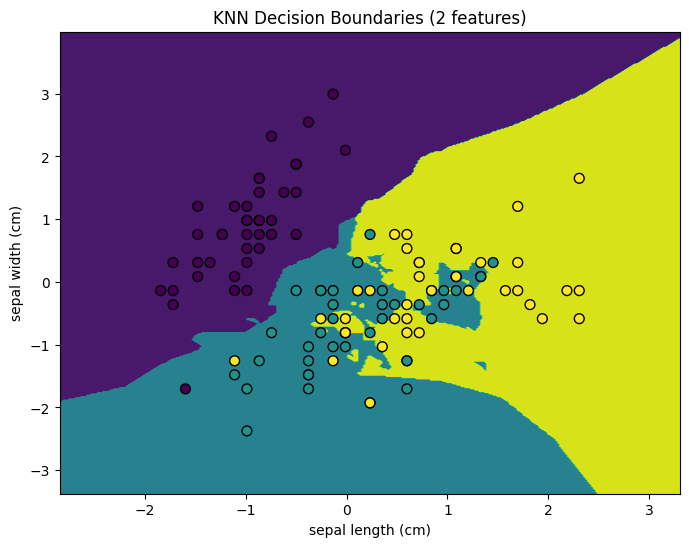

In [29]:
knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(X_train_scaled[:, :2], y_train)

Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z)
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, edgecolor='k', s=50)
plt.title("KNN Decision Boundaries (2 features)")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])
plt.show()
